# Credit Risk Strategy Simulation

## Project Overview

This project simulates a credit risk strategy optimization process using synthetic application data.

The objective is to identify high-risk applicants and improve portfolio risk quality while controlling approval-rate impact.

Dataset:
- Synthetic credit application dataset
- 10,000 applicants

Tools:
- Python
- Pandas
- NumPy
- Matplotlib

## 0. Project Objective

Business Objective:

Reduce approved portfolio bad rate while maintaining acceptable approval rate.

Constraint:

Approval loss should be controlled within 3 percentage points.

Methodology:

1. Data understanding
2. Risk factor analysis
3. Rule discovery
4. Rule combination optimization
5. Final policy evaluation

## 1. Data Generation

Generate synthetic credit application data to simulate lending scenarios.

In [147]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Credit Risk Project Started!")

Credit Risk Project Started!


In [148]:
np.random.seed(42)

n = 10000

df = pd.DataFrame({

    "applicant_id": range(1, n+1),

    "age": np.random.randint(
        18,61,n
    ),

    "monthly_income": np.random.randint(
        2500,50000,n
    ),

    "employment_years": np.random.uniform(
        0,30,n
    ),

    "credit_score": np.random.randint(
        450,802,n
    ),

    "debt_ratio": np.random.uniform(
        0.02,1,n
    ),

    "query_count_6m": np.random.poisson(
        3,n
    ),

    "overdue_count_12m": np.random.poisson(
        0.3,n
    ),

    "utilization": np.random.uniform(
        0.01,1,n
    ),

    "loan_amount": np.random.randint(
        5000,200000,n
    )
})


df.head()

,applicant_id,age,monthly_income,employment_years,credit_score,debt_ratio,query_count_6m,overdue_count_12m,utilization,loan_amount
0,1,56,25744,3.197923,692,0.401855,3,0,0.467464,45387
1,2,46,41485,3.506142,606,0.521105,5,0,0.263041,73340
2,3,32,40940,18.168744,714,0.954426,3,0,0.774233,146404
3,4,60,4002,29.505616,706,0.544798,3,1,0.740000,124887
4,5,25,36678,7.276184,792,0.995172,1,0,0.812825,60059


In [149]:
risk_score = (
    -0.8*(df["credit_score"]-650)/100
    +1.5*df["debt_ratio"]
    +0.3*df["query_count_6m"]
    +0.8*df["overdue_count_12m"]
    +1.2*df["utilization"]
)


prob = 1/(1+np.exp(-risk_score+5))


df["bad_90d"] = (
    np.random.random(n)
    < prob
).astype(int)


df.head()

,applicant_id,age,monthly_income,employment_years,credit_score,debt_ratio,query_count_6m,overdue_count_12m,utilization,loan_amount,bad_90d
0,1,56,25744,3.197923,692,0.401855,3,0,0.467464,45387,0
1,2,46,41485,3.506142,606,0.521105,5,0,0.263041,73340,0
2,3,32,40940,18.168744,714,0.954426,3,0,0.774233,146404,0
3,4,60,4002,29.505616,706,0.544798,3,1,0.740000,124887,0
4,5,25,36678,7.276184,792,0.995172,1,0,0.812825,60059,0


In [150]:
df.to_csv(
    "../data/credit_applications.csv",
    index=False
)

print("Data saved successfully!")

Data saved successfully!


## 2. Data Understanding & Quality Check

In [151]:
print("Dataset Shape:")
print(df.shape)


print("\nMissing Values:")
print(df.isnull().sum())


print("\nDuplicate Rows:")
print(df.duplicated().sum())


print("\nOverall Bad Rate:")
print(
    f"{df['bad_90d'].mean():.2%}"
)

Dataset Shape:
(10000, 11)

Missing Values:
applicant_id         0
age                  0
monthly_income       0
employment_years     0
credit_score         0
debt_ratio           0
query_count_6m       0
overdue_count_12m    0
utilization          0
loan_amount          0
bad_90d              0
dtype: int64

Duplicate Rows:
0

Overall Bad Rate:
13.55%


In [152]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
applicant_id,10000.0,5000.500000,2886.895680,1.000000,2500.750000,5000.500000,7500.250000,10000.000000
age,10000.0,39.002000,12.285800,18.000000,29.000000,39.000000,50.000000,60.000000
monthly_income,10000.0,25972.153700,13619.100634,2505.000000,13993.750000,25711.000000,37684.250000,49998.000000
employment_years,10000.0,14.936721,8.649506,0.000279,7.432843,14.787907,22.374941,29.996780
credit_score,10000.0,623.996000,102.215408,450.000000,535.000000,624.000000,711.000000,801.000000
debt_ratio,10000.0,0.508464,0.282749,0.020005,0.264375,0.508885,0.752039,0.999893
query_count_6m,10000.0,3.008500,1.734107,0.000000,2.000000,3.000000,4.000000,13.000000
overdue_count_12m,10000.0,0.301300,0.552222,0.000000,0.000000,0.000000,1.000000,4.000000
utilization,10000.0,0.501599,0.285235,0.010029,0.252482,0.503498,0.746010,0.999976
loan_amount,10000.0,101481.230500,56077.336394,5042.000000,52935.500000,101249.000000,150190.000000,199999.000000


## 3. Univariate Risk Analysis

Analyze the relationship between applicant characteristics and default risk.

In [153]:
def risk_band_analysis(
    df,
    column,
    bins,
    labels
):

    temp = df.copy()

    temp["band"] = pd.cut(
        temp[column],
        bins=bins,
        labels=labels
    )


    result = temp.groupby(
        "band",
        observed=False
    ).agg(
        applicants=("bad_90d","count"),
        bad_count=("bad_90d","sum"),
        bad_rate=("bad_90d","mean")
    )

    result["bad_rate"] = (
        result["bad_rate"]*100
    ).round(2)

    return result

### Credit Score

In [154]:
score_analysis = risk_band_analysis(
    df,
    "credit_score",
    [0,580,620,660,700,750,1000],
    [
        "<580",
        "580-619",
        "620-659",
        "660-699",
        "700-749",
        "750+"
    ]
)

score_analysis

,applicants,bad_count,bad_rate
band,,,
<580,3797,869,22.89
580-619,1097,126,11.49
620-659,1126,123,10.92
660-699,1184,91,7.69
700-749,1344,87,6.47
750+,1452,59,4.06


### Debt Ratio

In [155]:
debt_analysis = risk_band_analysis(
    df,
    "debt_ratio",
    [0,0.3,0.5,0.7,0.8,1],
    [
        "<30%",
        "30%-50%",
        "50%-70%",
        "70%-80%",
        "80%+"
    ]
)

debt_analysis

,applicants,bad_count,bad_rate
band,,,
<30%,2877,229,7.96
30%-50%,2031,255,12.56
50%-70%,2093,312,14.91
70%-80%,975,185,18.97
80%+,2024,374,18.48


### Query

In [156]:
query_analysis = risk_band_analysis(
    df,
    "query_count_6m",
    [-1,2,5,8,100],
    [
        "0-2",
        "3-5",
        "6-8",
        "9+"
    ]
)

query_analysis

,applicants,bad_count,bad_rate
band,,,
0-2,4192,386,9.21
3-5,4957,739,14.91
6-8,811,210,25.89
9+,40,20,50.00


### Overdue

In [157]:
overdue_analysis = (
df.groupby(
    "overdue_count_12m"
)["bad_90d"]
.agg(
    applicants="count",
    bad_count="sum",
    bad_rate="mean"
)
)

overdue_analysis["bad_rate"]*=100

overdue_analysis

,applicants,bad_count,bad_rate
overdue_count_12m,,,
0,7412,802,10.820291
1,2204,438,19.872958
2,349,98,28.080229
3,29,12,41.379310
4,6,5,83.333333


### Utilization

In [158]:
util_analysis = risk_band_analysis(
    df,
    "utilization",
    [0,0.3,0.5,0.7,0.85,1],
    [
        "<30%",
        "30%-50%",
        "50%-70%",
        "70%-85%",
        "85%+"
    ]
)

util_analysis

,applicants,bad_count,bad_rate
band,,,
<30%,2969,306,10.31
30%-50%,1995,238,11.93
50%-70%,2097,271,12.92
70%-85%,1456,246,16.90
85%+,1483,294,19.82


In [159]:
# prepare plotting dataframe

score_plot = score_analysis.reset_index()

debt_plot = debt_analysis.reset_index()

query_plot = query_analysis.reset_index()

overdue_plot = overdue_analysis.reset_index()

util_plot = util_analysis.reset_index()


print(score_plot.head())

      band  applicants  bad_count  bad_rate
0     <580        3797        869     22.89
1  580-619        1097        126     11.49
2  620-659        1126        123     10.92
3  660-699        1184         91      7.69
4  700-749        1344         87      6.47


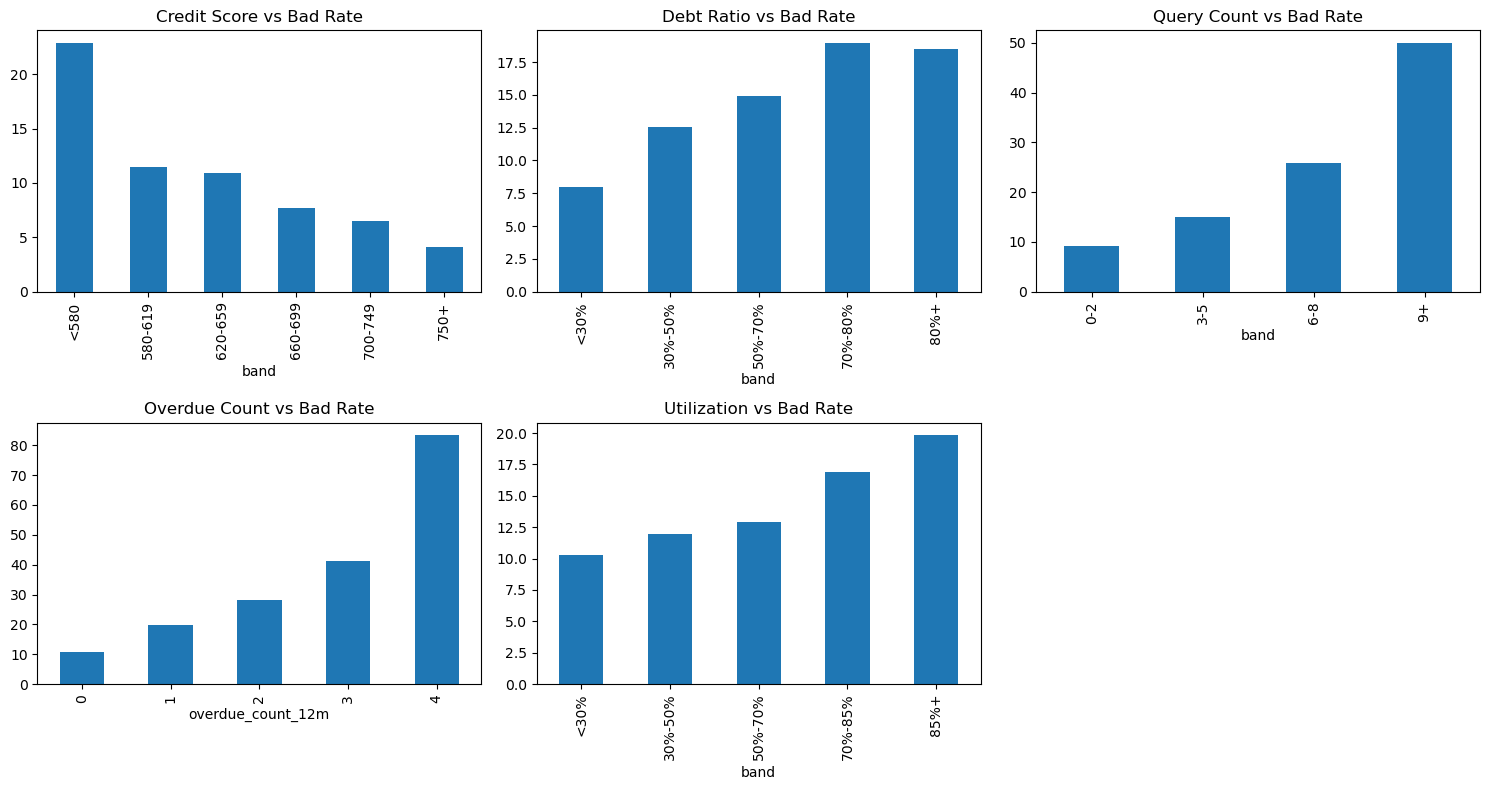

In [160]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(
    2,3,
    figsize=(15,8)
)


score_plot.plot(
    x="band",
    y="bad_rate",
    kind="bar",
    ax=axes[0,0],
    legend=False,
    title="Credit Score vs Bad Rate"
)


debt_plot.plot(
    x="band",
    y="bad_rate",
    kind="bar",
    ax=axes[0,1],
    legend=False,
    title="Debt Ratio vs Bad Rate"
)


query_plot.plot(
    x="band",
    y="bad_rate",
    kind="bar",
    ax=axes[0,2],
    legend=False,
    title="Query Count vs Bad Rate"
)


overdue_plot.plot(
    x="overdue_count_12m",
    y="bad_rate",
    kind="bar",
    ax=axes[1,0],
    legend=False,
    title="Overdue Count vs Bad Rate"
)


util_plot.plot(
    x="band",
    y="bad_rate",
    kind="bar",
    ax=axes[1,1],
    legend=False,
    title="Utilization vs Bad Rate"
)


axes[1,2].axis("off")


plt.tight_layout()


plt.savefig(
    "../assets/risk_factor_analysis.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

### Initial Findings

1. Lower credit score is associated with higher default risk.
2. Higher debt ratio indicates higher risk concentration.
3. Frequent credit inquiries show increased default probability.
4. Historical overdue behavior is a strong risk indicator.
5. High utilization ratio indicates elevated risk.

## 4. Baseline Credit Policy

Establish a baseline approval policy to evaluate portfolio risk before applying additional risk rules.

Baseline assumption:

All applicants are approved initially.

In [161]:
# Baseline approval

approved_df = df.copy()

approved_count = len(approved_df)

approved_bad_count = approved_df["bad_90d"].sum()

approval_rate = (
    approved_count / len(df)
)

bad_rate = (
    approved_bad_count / approved_count
)


print(
    f"Approved Applicants: {approved_count}"
)

print(
    f"Approval Rate: {approval_rate:.2%}"
)

print(
    f"Approved Bad Count: {approved_bad_count}"
)

print(
    f"Approved Bad Rate: {bad_rate:.2%}"
)

Approved Applicants: 10000
Approval Rate: 100.00%
Approved Bad Count: 1355
Approved Bad Rate: 13.55%


## 5. Candidate Rule Evaluation

Evaluate individual risk rules based on:

1. Risk identification capability
2. Bad rate among rejected applicants
3. Approval impact

In [162]:
def evaluate_rule(df, rule_name, condition):

    reject = df[condition]

    hit_count = len(reject)

    hit_rate = (
        hit_count / len(df)
    )

    hit_bad_rate = (
        reject["bad_90d"].mean()
    )

    bad_capture_rate = (
        reject["bad_90d"].sum()
        /
        df["bad_90d"].sum()
    )


    return pd.DataFrame({

        "rule":[rule_name],

        "hit_count":[hit_count],

        "hit_rate":[round(hit_rate*100,2)],

        "hit_bad_rate":[round(hit_bad_rate*100,2)],

        "bad_capture_rate":[round(bad_capture_rate*100,2)]
    })

In [163]:
rules = []


rules.append(
evaluate_rule(
    df,
    "R001 Debt Ratio >=70%",
    df["debt_ratio"]>=0.7
))


rules.append(
evaluate_rule(
    df,
    "R002 Query Count >=6",
    df["query_count_6m"]>=6
))


rules.append(
evaluate_rule(
    df,
    "R003 Overdue Count >=2",
    df["overdue_count_12m"]>=2
))


rules.append(
evaluate_rule(
    df,
    "R004 Utilization >=70%",
    df["utilization"]>=0.7
))


candidate_rules = pd.concat(
    rules
)

candidate_rules

,rule,hit_count,hit_rate,hit_bad_rate,bad_capture_rate
0,R001 Debt Ratio >=70%,2999,29.99,18.64,41.25
0,R002 Query Count >=6,851,8.51,27.03,16.97
0,R003 Overdue Count >=2,384,3.84,29.95,8.49
0,R004 Utilization >=70%,2939,29.39,18.37,39.85


### Findings

Individual rules show different risk discrimination ability.

High-risk indicators:

- High debt ratio
- Frequent credit inquiries
- High utilization

However, individual rules may reject too many customers or miss overlapping risk segments.

## 6. Combination Rule Analysis

Combine multiple risk factors to identify higher-risk customer segments.

In [164]:
combination_rules = []


conditions = {

"C001 Debt>=70% AND Query>=6":

(df["debt_ratio"]>=0.7)
&
(df["query_count_6m"]>=6),


"C002 Debt>=70% AND Util>=70%":

(df["debt_ratio"]>=0.7)
&
(df["utilization"]>=0.7),


"C003 Query>=6 AND Util>=70%":

(df["query_count_6m"]>=6)
&
(df["utilization"]>=0.7),


"C004 Score<660 AND Query>=6":

(df["credit_score"]<660)
&
(df["query_count_6m"]>=6)

}


for name,condition in conditions.items():

    combination_rules.append(
        evaluate_rule(
            df,
            name,
            condition
        )
    )


combination_result = pd.concat(
    combination_rules
)


combination_result

,rule,hit_count,hit_rate,hit_bad_rate,bad_capture_rate
0,C001 Debt>=70% AND Query>=6,233,2.33,34.33,5.90
0,C002 Debt>=70% AND Util>=70%,867,8.67,23.99,15.35
0,C003 Query>=6 AND Util>=70%,241,2.41,32.78,5.83
0,C004 Score<660 AND Query>=6,511,5.11,36.79,13.87


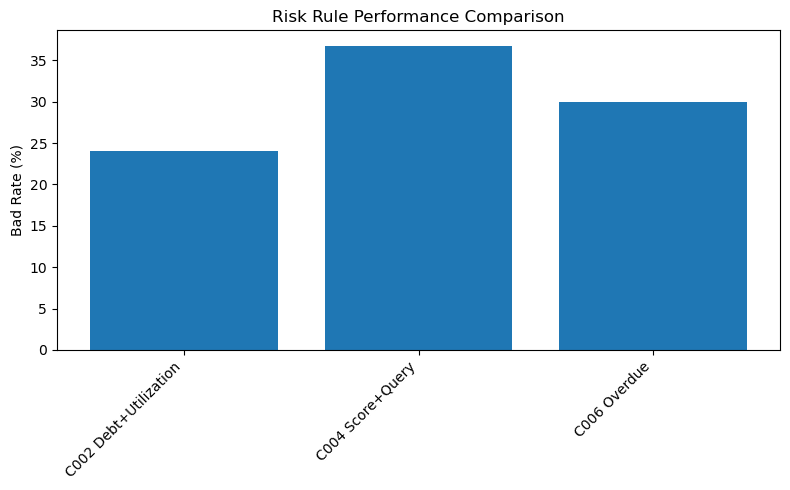

In [165]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8,5))


plt.bar(
    rule_summary["Rule"],
    rule_summary["Bad Rate"]
)


plt.xticks(
    rotation=45,
    ha="right"
)


plt.ylabel(
    "Bad Rate (%)"
)


plt.title(
    "Risk Rule Performance Comparison"
)


plt.tight_layout()


plt.savefig(
    "../assets/strategy_result.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

### Findings

Combination rules improve risk concentration compared with single-variable rules.

The best candidates should balance:

- High bad rate
- High bad capture
- Limited approval loss

## 7. Incremental Rule Analysis

Evaluate incremental contribution of additional rules after applying the initial risk strategy.

In [166]:
base_condition = (

(df["debt_ratio"]>=0.7)

&

(df["utilization"]>=0.7)

)


base_reject = base_condition


candidates = {

"C001":

(df["debt_ratio"]>=0.7)
&
(df["query_count_6m"]>=6),


"C003":

(df["query_count_6m"]>=6)
&
(df["utilization"]>=0.7),


"C004":

(df["credit_score"]<660)
&
(df["query_count_6m"]>=6)

}



incremental_result=[]


for name,cond in candidates.items():

    incremental = cond & (~base_reject)

    incremental_result.append(

        evaluate_rule(
            df,
            name,
            incremental
        )

    )


incremental_result = pd.concat(
    incremental_result
)


incremental_result

,rule,hit_count,hit_rate,hit_bad_rate,bad_capture_rate
0,C001,156,1.56,28.85,3.32
0,C003,164,1.64,26.83,3.25
0,C004,465,4.65,35.05,12.03


## 8. Final Policy Evaluation

Evaluate the final risk strategy performance.

In [167]:
# Final Credit Strategy


rule_c002 = (
    (df["debt_ratio"] >= 0.7)
    &
    (df["utilization"] >= 0.7)
)


rule_c004 = (
    (df["credit_score"] < 660)
    &
    (df["query_count_6m"] >= 6)
)


rule_c006 = (
    df["overdue_count_12m"] >= 2
)


final_reject = (
    rule_c002
    |
    rule_c004
    |
    rule_c006
)


final_approve = df[~final_reject]


print(
    "Rejected Applicants:",
    final_reject.sum()
)


print(
    "Approved Applicants:",
    len(final_approve)
)


print(
    "Final Approval Rate:",
    f"{len(final_approve)/len(df):.2%}"
)


print(
    "Final Bad Rate:",
    f"{final_approve['bad_90d'].mean():.2%}"
)

Rejected Applicants: 1670
Approved Applicants: 8330
Final Approval Rate: 83.30%
Final Bad Rate: 10.79%


In [168]:
rule_summary = pd.DataFrame({

"Rule":[
"C002 Debt+Utilization",
"C004 Score+Query",
"C006 Overdue"
],


"Applicants":[
rule_c002.sum(),
rule_c004.sum(),
rule_c006.sum()
],


"Bad Rate":[

df[rule_c002]["bad_90d"].mean(),

df[rule_c004]["bad_90d"].mean(),

df[rule_c006]["bad_90d"].mean()

]

})


rule_summary["Bad Rate"] = (
    rule_summary["Bad Rate"]*100
).round(2)


rule_summary

,Rule,Applicants,Bad Rate
0,C002 Debt+Utilization,867,23.99
1,C004 Score+Query,511,36.79
2,C006 Overdue,384,29.95


### Risk Lift Analysis

Risk Lift measures how much higher the risk concentration is within rejected applicants compared with the overall portfolio.

In [169]:
overall_bad_rate = df["bad_90d"].mean()


rejected_bad_rate = (
    df[final_reject]["bad_90d"]
    .mean()
)


risk_lift = (
    rejected_bad_rate
    /
    overall_bad_rate
)


print(
    f"Overall Bad Rate: {overall_bad_rate:.2%}"
)


print(
    f"Rejected Bad Rate: {rejected_bad_rate:.2%}"
)


print(
    f"Risk Lift: {risk_lift:.2f}x"
)

Overall Bad Rate: 13.55%
Rejected Bad Rate: 27.31%
Risk Lift: 2.02x


In [170]:
approval_loss = (
1 - len(final_approve)/len(df)
)


print(
f"Approval Loss: {approval_loss:.2%}"
)

Approval Loss: 16.70%


## 9. Final Policy Visualization

Compare baseline and final policy performance.

In [171]:
final_approve_df = df[~final_reject]

final_approval_rate = len(final_approve_df) / len(df)
final_bad_rate = final_approve_df["bad_90d"].mean()


In [172]:
comparison = pd.DataFrame({

"Policy":
[
"Baseline",
"Final Policy"
],

"Approval Rate":
[
approval_rate,
final_approval_rate
],

"Bad Rate":
[
bad_rate,
final_bad_rate
]

})


comparison

,Policy,Approval Rate,Bad Rate
0,Baseline,1.000,0.135500
1,Final Policy,0.833,0.107923


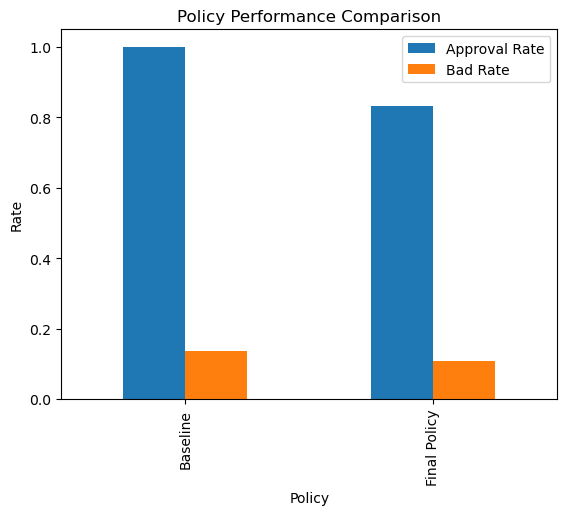

In [173]:
comparison.set_index(
"Policy"
)[
["Approval Rate","Bad Rate"]
].plot(
kind="bar"
)

plt.title(
"Policy Performance Comparison"
)

plt.ylabel(
"Rate"
)

plt.show()

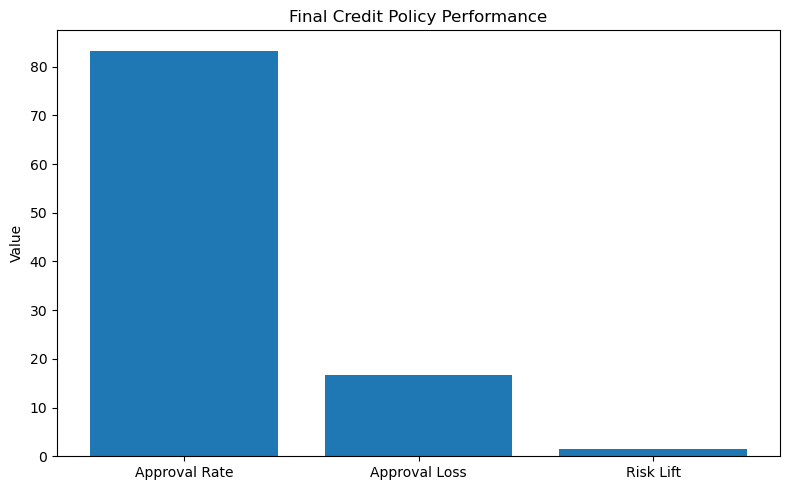

In [174]:
import matplotlib.pyplot as plt


metrics = {
    "Approval Rate":83.3,
    "Approval Loss":16.7,
    "Risk Lift":1.45
}


plt.figure(figsize=(8,5))


plt.bar(
    metrics.keys(),
    metrics.values()
)


plt.title(
    "Final Credit Policy Performance"
)


plt.ylabel(
    "Value"
)


plt.tight_layout()


plt.savefig(
    "../assets/final_policy_result.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

## 10. Monitoring Framework

A production credit strategy requires continuous monitoring.

### Portfolio Monitoring

Key metrics:

1. Approval Rate
2. Bad Rate
3. Rule Hit Rate
4. Risk Lift
5. Population Stability Index (PSI)


### Rule Monitoring

Monitor:

- Rule trigger volume
- Default rate by rule
- Rule effectiveness over time

## 11. Sensitivity Analysis

Test threshold changes and evaluate strategy robustness.

In [175]:
threshold_result=[]


for threshold in [0.6,0.7,0.8]:

    reject = (
        df["debt_ratio"]
        >=threshold
    )


    approved=df[~reject]


    threshold_result.append({

        "Debt Threshold":threshold,

        "Approval Rate":
        len(approved)/len(df),


        "Bad Rate":
        approved["bad_90d"].mean()

    })


pd.DataFrame(
threshold_result
)

,Debt Threshold,Approval Rate,Bad Rate
0,0.6,0.5950,0.109076
1,0.7,0.7001,0.113698
2,0.8,0.7976,0.122994


In [176]:
baseline_bad_rate = df["bad_90d"].mean()


final_bad_rate = df[~final_reject]["bad_90d"].mean()


comparison = pd.DataFrame({

    "Strategy":[
        "Baseline",
        "Final Policy"
    ],

    "Bad Rate":[
        baseline_bad_rate*100,
        final_bad_rate*100
    ]

})


comparison

,Strategy,Bad Rate
0,Baseline,13.550000
1,Final Policy,10.792317


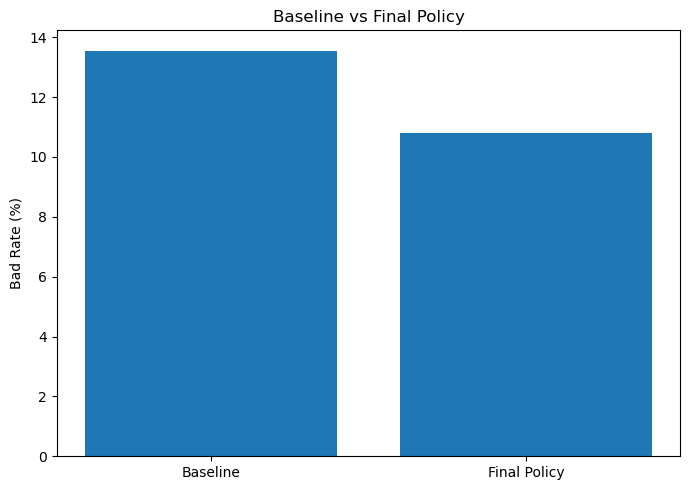

In [177]:
plt.figure(figsize=(7,5))


plt.bar(
    comparison["Strategy"],
    comparison["Bad Rate"]
)


plt.ylabel(
    "Bad Rate (%)"
)


plt.title(
    "Baseline vs Final Policy"
)


plt.tight_layout()


plt.savefig(
    "../assets/strategy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

## 12. Conclusion

Key Findings:

1. Credit score, debt ratio, inquiry frequency, overdue history and utilization are important risk drivers.

2. Combination rules provide stronger risk differentiation than single-variable rules.

3. Final strategy improves portfolio risk quality while controlling approval impact.

4. A production credit strategy requires continuous monitoring and threshold optimization.


Limitations:

- Synthetic dataset
- No external macroeconomic factors
- No machine learning model included

### Dataset Note

The dataset is synthetically generated for strategy simulation.

The default label (bad_90d) is generated based on risk characteristics to simulate realistic credit risk patterns.